# Data consistency check — 4-tank pilot plant recordings

Self-contained notebook. Reads every Rockwell trend export in `data/`, checks each file on its own
(time base, duplicates, stale samples), then checks the files against each other (time overlap,
shared tags, clock offsets), and finally writes one aligned table to `processed/merged.csv`
for the cleaning notebook.

Nothing here modifies the raw files.

In [21]:
from pathlib import Path
from collections import defaultdict
import csv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("data")
OUT_DIR = Path("processed")
TS = 0.1                      # sample time [s]
TOL = pd.Timedelta(seconds=TS / 2)
REFERENCE = "Flujos"          # file whose clock the others are aligned to

pd.set_option("display.width", 160)

## 1. Load all files

Each export has a metadata block, a header line starting with `Encabezado:`, and data rows starting
with `Datos`. Tag names are read from each file's own header, so files with different tags load the
same way. Time is kept as `hora` (absolute time of day) so the files can be aligned.

In [22]:
def read_trend(path):
    """Read a Rockwell trend export (cp1252, metadata block, 'Datos' rows)."""
    lines = Path(path).read_text(encoding="cp1252").splitlines()
    hdr = next(i for i, l in enumerate(lines) if l.startswith("Encabezado"))
    names = next(csv.reader([lines[hdr]]))[1:]                 # Fecha, Hora, tags...
    rows = [r[1:] for r in csv.reader(lines[hdr + 1:]) if r and r[0] == "Datos"]
    df = pd.DataFrame(rows, columns=names)
    tags = names[2:]
    df[tags] = df[tags].astype(float)
    df["hora"] = pd.to_timedelta(df["Hora"].str.replace(";", ".", regex=False))
    df.attrs["dates"] = sorted(df["Fecha"].unique())
    return df.drop(columns=["Fecha", "Hora"])


files = sorted(p for p in DATA_DIR.iterdir() if p.suffix.lower() == ".csv")
dfs = {p.stem: read_trend(p) for p in files}

for k, d in dfs.items():
    tags = [c for c in d.columns if c != "hora"]
    print(f"{k:10s} {len(d):6d} rows  dates={d.attrs['dates']}  tags={tags}")

Flujos      60000 rows  dates=['10/8/2026']  tags=['VF01', 'VF02', 'FIT_01', 'FIT_02', 'SP_F1']
Nivel_1     60000 rows  dates=['10/8/2026']  tags=['LIT_01', 'SP_L1', 'Program:ControlProgram\\CV_L1', 'LIT_03', 'FIT_01', 'FIT_02']
Nivel_2     60000 rows  dates=['10/8/2026']  tags=['LIT_02', 'SP_L2', 'Program:ControlProgram\\CV_L2', 'LIT_04', 'FIT_02']
Nivel_3     60000 rows  dates=['10/8/2026']  tags=['LIT_03', 'SP_L3', 'Program:ControlProgram\\CV_L3', 'FIT_02']
Nivel_4     60000 rows  dates=['10/8/2026']  tags=['SP_L4', 'LIT_04', 'Program:ControlProgram\\CV_L4', 'FIT_01']


## 1b. Remove controller variables

Setpoints (`SP_…`) and controller outputs (`…CV_…`) describe what the controller was asked to do,
not what the plant did. In manual mode they carry no information for identification.
Actuator commands (`VF01`, `VF02`) are **kept**: they tell whether each pump was on, which is needed
later to zero the flowmeter noise when a pump is off.

In [23]:
def is_controller_var(tag):
    return tag.startswith("SP_") or "CV_" in tag

for k, d in dfs.items():
    drop = [c for c in d.columns if is_controller_var(c)]
    d.drop(columns=drop, inplace=True)
    print(f"{k:10s} dropped {drop}")

Flujos     dropped ['SP_F1']
Nivel_1    dropped ['SP_L1', 'Program:ControlProgram\\CV_L1']
Nivel_2    dropped ['SP_L2', 'Program:ControlProgram\\CV_L2']
Nivel_3    dropped ['SP_L3', 'Program:ControlProgram\\CV_L3']
Nivel_4    dropped ['SP_L4', 'Program:ControlProgram\\CV_L4']


## 1c. Repair sensor glitches (Hampel filter)

Each sample is compared with the median of a window centred on it. The median ignores excursions
shorter than half the window, so a glitch stands out as a large distance from it.
Flagged samples are **replaced by the rolling median** (keeps the signal continuous for filtering and
differentiation later) and **marked** in a `flag_<tag>` column, so the cleaning notebook can exclude
them — and their neighbours — from the training targets.

- `window` must be more than twice as long as the longest glitch (101 samples = 10 s).
- `min_dev` is the smallest deviation ever treated as an error, in the signal's units (%).

In [24]:
HAMPEL_TAGS = ["LIT_03"]
WINDOW, K, MIN_DEV = 101, 6, 2.0

def hampel(s, window=WINDOW, k=K, min_dev=MIN_DEV):
    med = s.rolling(window, center=True, min_periods=1).median()
    res = (s - med).abs()
    sigma = 1.4826 * res.median()                 # robust noise level
    return res > max(k * sigma, min_dev), med

raw_copies = {}                                    # originals, only for the plot below
for k, d in dfs.items():
    for tag in HAMPEL_TAGS:
        if tag not in d.columns:
            continue
        bad, med = hampel(d[tag])
        raw_copies[(k, tag)] = d[tag].copy()
        d.loc[bad, tag] = med[bad]
        d[f"flag_{tag}"] = bad
        n_events = int((bad & ~bad.shift(fill_value=False)).sum())
        print(f"{k:10s} {tag}: {int(bad.sum())} samples repaired in {n_events} event(s)")

Nivel_1    LIT_03: 40 samples repaired in 1 event(s)
Nivel_3    LIT_03: 40 samples repaired in 1 event(s)


Before / after around each repaired event (±20 s).

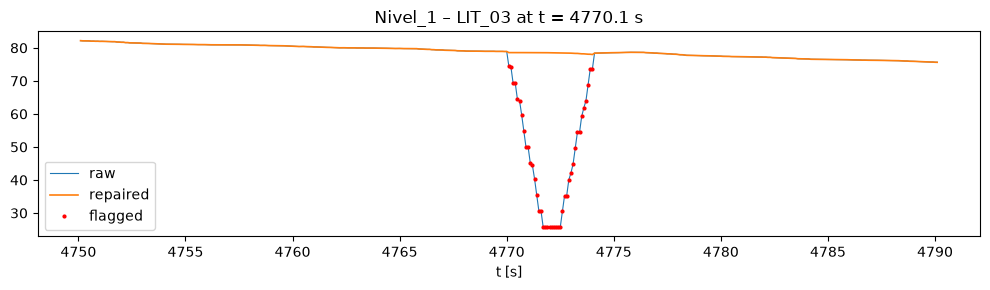

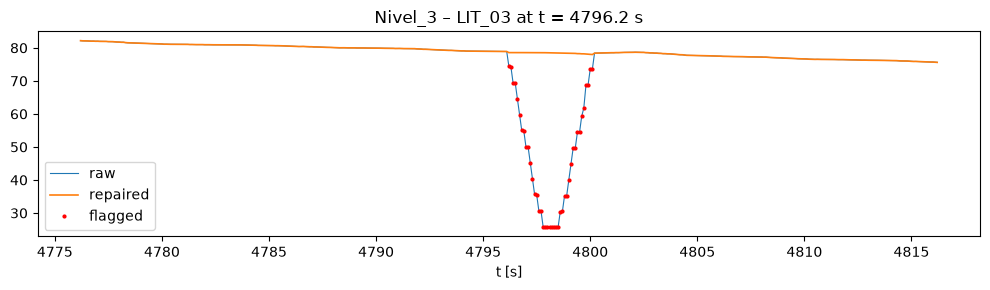

In [25]:
for (k, tag), raw in raw_copies.items():
    d = dfs[k]
    flag = d[f"flag_{tag}"]
    starts = d.index[flag & ~flag.shift(fill_value=False)]
    for i in starts[:5]:                           # first 5 events per file
        w = slice(max(i - 200, 0), i + 200)
        t = (d.loc[w, "hora"] - d["hora"].iloc[0]).dt.total_seconds()
        fig, ax = plt.subplots(figsize=(10, 3))
        ax.plot(t, raw.loc[w], lw=0.8, label="raw")
        ax.plot(t, d.loc[w, tag], lw=1.2, label="repaired")
        ax.plot(t[flag.loc[w]], raw.loc[w][flag.loc[w]], "r.", ms=4, label="flagged")
        ax.set_title(f"{k} – {tag} at t = {t.loc[i]:.1f} s"); ax.set_xlabel("t [s]"); ax.legend()
        plt.tight_layout(); plt.show()

## 2. Checks within each file

| Column | Meaning |
|---|---|
| `steps` | Distinct time steps found; should be only 0.1 s |
| `gaps` | Steps longer than the sample time (missing samples) |
| `dup_time` | Timestamps written twice |
| `dup_rows` | Fully identical rows, time included |
| `stale_rows` | Rows where **every** measured signal (LIT/FIT) equals the previous row — with sensor noise at 100 ms this should be ~0 |
| `longest_frozen_s` | Longest run of identical values in any single LIT/FIT tag |
| `multi_date` | Recording crosses midnight (time-of-day alignment would break) |

In [26]:
def longest_run(s):
    same = s.eq(s.shift())
    runs = same.groupby((~same).cumsum()).sum()
    return int(runs.max()) if len(runs) else 0

rows = {}
for k, d in dfs.items():
    dt = d["hora"].diff().dt.total_seconds().round(3)
    pv = [c for c in d.columns if c.startswith(("LIT", "FIT"))]
    stale = d[pv].eq(d[pv].shift()).all(axis=1) if pv else pd.Series(False, index=d.index)
    frozen = {c: longest_run(d[c]) * TS for c in pv}
    rows[k] = {
        "steps": sorted(dt.dropna().unique().tolist())[:5],
        "gaps": int((dt > TS * 1.5).sum()),
        "monotonic": d["hora"].is_monotonic_increasing,
        "dup_time": int(d["hora"].duplicated().sum()),
        "dup_rows": int(d.duplicated().sum()),
        "stale_rows": int(stale.sum()),
        "longest_frozen_s": max(frozen.values()) if frozen else 0,
        "frozen_tag": max(frozen, key=frozen.get) if frozen else None,
        "multi_date": len(d.attrs["dates"]) > 1,
    }
per_file = pd.DataFrame(rows).T
per_file

,steps,gaps,monotonic,dup_time,dup_rows,stale_rows,longest_frozen_s,frozen_tag,multi_date
Flujos,[0.1],0,True,0,0,1,0.1,FIT_01,False
Nivel_1,[0.1],0,True,0,0,0,1.2,LIT_03,False
Nivel_2,[0.1],0,True,0,0,0,0.2,LIT_02,False
Nivel_3,[0.1],0,True,0,0,1,1.2,LIT_03,False
Nivel_4,[0.1],0,True,0,0,0,0.1,LIT_04,False


## 3. Time overlap

Mass balances need several files at the same instant, so only the window covered by **all** files is usable.

In [27]:
span = pd.DataFrame({k: {"start": d["hora"].iloc[0], "end": d["hora"].iloc[-1],
                         "duration_min": (d["hora"].iloc[-1] - d["hora"].iloc[0]).total_seconds() / 60}
                     for k, d in dfs.items()}).T
common_start, common_end = span["start"].max(), span["end"].min()
print(span)
print(f"\ncommon window: {common_start} -> {common_end} "
      f"({(common_end - common_start).total_seconds() / 60:.1f} min)")

                          start                     end duration_min
Flujos   0 days 17:37:13.012000  0 days 19:17:12.912000    99.998333
Nivel_1  0 days 17:40:55.972000  0 days 19:20:55.872000    99.998333
Nivel_2  0 days 17:40:42.525000  0 days 19:20:42.425000    99.998333
Nivel_3  0 days 17:40:29.893000  0 days 19:20:29.793000    99.998333
Nivel_4  0 days 17:40:14.893000  0 days 19:20:14.793000    99.998333

common window: 0 days 17:40:55.972000 -> 0 days 19:17:12.912000 (96.3 min)


## 4. Which tag is recorded in which file

In [28]:
where = defaultdict(list)
for k, d in dfs.items():
    for c in d.columns:
        if c != "hora":
            where[c].append(k)

inventory = pd.DataFrame({t: {f: (f in srcs) for f in dfs} for t, srcs in where.items()}).T
inventory["n_files"] = inventory.sum(axis=1)
inventory.sort_values("n_files", ascending=False)

,Flujos,Nivel_1,Nivel_2,Nivel_3,Nivel_4,n_files
FIT_02,True,True,True,True,False,4
FIT_01,True,True,False,False,True,3
LIT_04,False,False,True,False,True,2
flag_LIT_03,False,True,False,True,False,2
LIT_03,False,True,False,True,False,2
VF01,True,False,False,False,False,1
VF02,True,False,False,False,False,1
LIT_01,False,True,False,False,False,1
LIT_02,False,False,True,False,False,1


## 5. Do the copies of shared tags agree?

For every measured tag that appears in more than one file, both copies are aligned on `hora` and
compared. One copy is also shifted by up to ±`MAX_LAG` samples, to detect a clock offset between files.

- **best lag 0, error ≈ 0** → same signal, same clock: merging on `hora` is safe.
- **best lag ≠ 0, small error there** → that file's clock is offset by `lag` samples.
- **large error at every lag** → not the same signal (scaling, different tag, data problem). Plot it.

In [29]:
MAX_LAG = 50   # samples (5 s)

def compare(tag, f1, f2):
    a, b = dfs[f1][["hora", tag]], dfs[f2][["hora", tag]]
    m = pd.merge_asof(a.sort_values("hora"), b.sort_values("hora"), on="hora", tolerance=TOL,
                      direction="nearest", suffixes=("_1", "_2")).dropna()
    err = {lag: (m[f"{tag}_1"] - m[f"{tag}_2"].shift(lag)).abs().mean()
           for lag in range(-MAX_LAG, MAX_LAG + 1)}
    best = min(err, key=err.get)
    return {"tag": tag, "file_1": f1, "file_2": f2, "overlap_samples": len(m),
            "mean_abs_diff_lag0": err[0], "max_abs_diff_lag0": (m[f"{tag}_1"] - m[f"{tag}_2"]).abs().max(),
            "best_lag_samples": best, "mean_abs_diff_best": err[best]}

results = []
for tag, srcs in where.items():
    if tag.startswith(("LIT", "FIT")) and len(srcs) > 1:
        for f2 in srcs[1:]:
            results.append(compare(tag, srcs[0], f2))

shared = pd.DataFrame(results)
shared.round(4) if len(shared) else print("no measured tag appears in more than one file")

,tag,file_1,file_2,overlap_samples,mean_abs_diff_lag0,max_abs_diff_lag0,best_lag_samples,mean_abs_diff_best
0,FIT_01,Flujos,Nivel_1,57770,0.0087,0.1880,0,0.0087
1,FIT_01,Flujos,Nivel_4,58181,0.0042,0.1795,0,0.0042
2,FIT_02,Flujos,Nivel_1,57770,0.0099,5.0695,0,0.0099
3,FIT_02,Flujos,Nivel_2,57905,0.0031,3.4455,0,0.0031
4,FIT_02,Flujos,Nivel_3,58031,0.0046,4.0805,0,0.0046
5,LIT_03,Nivel_1,Nivel_3,59739,0.0032,0.7636,0,0.0032
6,LIT_04,Nivel_2,Nivel_4,59724,0.0048,0.7098,0,0.0048


Visual check of every shared tag: all copies on one time axis (relative to the reference file).

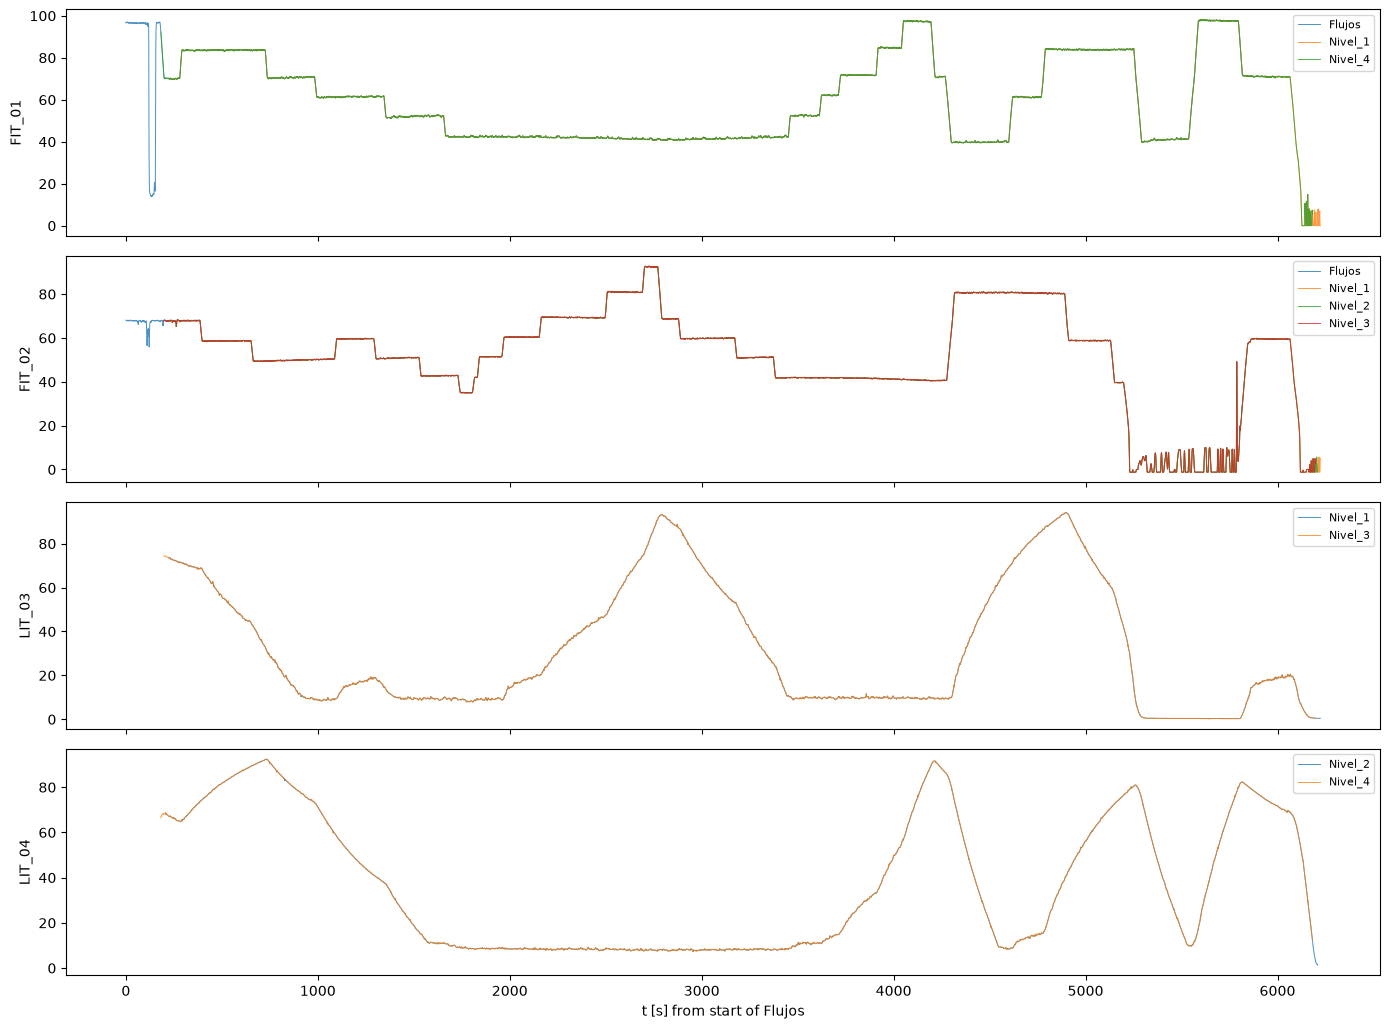

In [30]:
t0 = dfs[REFERENCE]["hora"].iloc[0] if REFERENCE in dfs else min(d["hora"].iloc[0] for d in dfs.values())
multi = [t for t, s in where.items() if t.startswith(("LIT", "FIT")) and len(s) > 1]

if multi:
    fig, axes = plt.subplots(len(multi), 1, figsize=(14, 2.6 * len(multi)), sharex=True, squeeze=False)
    for ax, tag in zip(axes[:, 0], multi):
        for f in where[tag]:
            d = dfs[f]
            ax.plot((d["hora"] - t0).dt.total_seconds(), d[tag], lw=0.7, label=f, alpha=0.8)
        ax.set_ylabel(tag); ax.legend(loc="upper right", fontsize=8)
    axes[-1, 0].set_xlabel(f"t [s] from start of {REFERENCE}")
    plt.tight_layout(); plt.show()

## 6. Clock offsets relative to the reference file

From the comparisons above, each file's offset to `REFERENCE` (via any measured tag they share).
A positive lag means that file recorded each value `lag` samples too early, so its timestamps are moved later by `lag × TS`.
Set `APPLY_OFFSETS = True` only after the table and plots confirm a real, consistent offset.

In [31]:
APPLY_OFFSETS = False

offsets = {}
for k in dfs:
    if k == REFERENCE:
        offsets[k] = 0
        continue
    common = [t for t in where if t.startswith(("LIT", "FIT")) and REFERENCE in where[t] and k in where[t]]
    lags = [compare(t, REFERENCE, k)["best_lag_samples"] for t in common]
    offsets[k] = int(np.median(lags)) if lags else None
    print(f"{k:10s} shared with {REFERENCE}: {common}  lags={lags}  -> offset={offsets[k]}")

if APPLY_OFFSETS:
    for k, lag in offsets.items():
        if lag:
            dfs[k]["hora"] = dfs[k]["hora"] + pd.Timedelta(seconds=lag * TS)
            print(f"shifted {k} by {lag * TS:+.1f} s")

Nivel_1    shared with Flujos: ['FIT_01', 'FIT_02']  lags=[0, 0]  -> offset=0
Nivel_2    shared with Flujos: ['FIT_02']  lags=[0]  -> offset=0
Nivel_3    shared with Flujos: ['FIT_02']  lags=[0]  -> offset=0
Nivel_4    shared with Flujos: ['FIT_01']  lags=[0]  -> offset=0


## 7. Build one aligned table

One source per tag:
- `LIT_0n` from `Nivel_n` (its own file),
- flows and valve commands from `Flujos`,
- anything else from the first file that has it.

Rows are taken on the reference clock inside the common window; each other file is matched to the
nearest sample within ±half a sample time.

In [32]:
def source_for(tag):
    srcs = where[tag]
    if tag.startswith("flag_"):                       # a repair flag follows its signal's source
        sig_src = source_for(tag[len("flag_"):])
        if sig_src in srcs:
            return sig_src
    if tag.startswith("LIT_"):
        own = f"Nivel_{int(tag.split('_')[1])}"
        if own in srcs:
            return own
    if "Flujos" in srcs and tag.startswith(("FIT", "VF")):
        return "Flujos"
    return srcs[0]

chosen = {t: source_for(t) for t in where}
print(pd.Series(chosen, name="source").sort_index())

ref = REFERENCE if REFERENCE in dfs else next(iter(dfs))
base = dfs[ref].loc[dfs[ref]["hora"].between(common_start, common_end), ["hora"]].sort_values("hora")

merged = base
for f in dfs:
    cols = [t for t, s in chosen.items() if s == f]
    if cols:
        part = dfs[f][["hora"] + cols].sort_values("hora")
        merged = pd.merge_asof(merged, part, on="hora", tolerance=TOL, direction="nearest")

merged["t_s"] = (merged["hora"] - merged["hora"].iloc[0]).dt.total_seconds()
print(f"\nmerged: {merged.shape}, NaN per column:")
print(merged.isna().sum()[merged.isna().sum() > 0] if merged.isna().any().any() else "  none")

FIT_01          Flujos
FIT_02          Flujos
LIT_01         Nivel_1
LIT_02         Nivel_2
LIT_03         Nivel_3
LIT_04         Nivel_4
VF01            Flujos
VF02            Flujos
flag_LIT_03    Nivel_3
Name: source, dtype: str

merged: (57770, 11), NaN per column:
  none


## 8. Save

`hora` is saved as seconds of the day so the CSV round-trips cleanly.

In [33]:
OUT_DIR.mkdir(exist_ok=True)
out = merged.copy()
out["hora_s"] = out.pop("hora").dt.total_seconds()
out.to_csv(OUT_DIR / "merged.csv", index=False)
print("written", OUT_DIR / "merged.csv", out.shape)

written processed/merged.csv (57770, 11)
